# Self-organised criticality in the Drossel–Schwabl forest-fire model

This notebook measures the statistics of the model in **instantaneous mode** (see
`docs/adr/0001-two-simulation-modes.md`): each *event* makes θ planting attempts on random
cells, then strikes one random cell, burning the struck tree's whole cluster at once.

We look at four things:

1. The approach of the tree density to its **stationary state**.
2. The **fire-size distribution** n(s), and its exponent τ fitted by discrete maximum
   likelihood (Clauset, Shalizi & Newman 2009).
3. How the distribution's **cutoff** moves with θ and the lattice size L.
4. Why the model's criticality comes with an important caveat.

Set the environment variable `FOREST_FIRE_QUICK=1` to run everything on tiny lattices (as CI
does); the figures in the README come from a full run.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from forest_fire import instantaneous, powerlaw

QUICK = os.environ.get("FOREST_FIRE_QUICK") == "1"
ASSETS = Path("../docs/assets")

L = 64 if QUICK else 512
THETA = 50 if QUICK else 500
BURN_IN = 500 if QUICK else 20_000
EVENTS = 2_000 if QUICK else 200_000
rng = np.random.default_rng(2024)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def run(size, theta, events, burn_in, rng):
    params = instantaneous.Params(theta=theta)
    start = np.zeros((size, size), dtype=np.int8)
    warm = instantaneous.simulate(start, params, burn_in, rng)
    return warm, instantaneous.simulate(warm.grid, params, events, rng)


def log_binned(sizes, bins_per_decade=8):
    """Density n(s) on logarithmic bins, normalised per unit s; for plotting only."""
    edges = np.unique(np.logspace(0, np.log10(sizes.max() + 1), 1 + int(
        bins_per_decade * np.log10(sizes.max() + 1))).astype(int))
    counts, _ = np.histogram(sizes, edges)
    centres = np.sqrt(edges[:-1] * edges[1:])
    keep = counts > 0
    return centres[keep], (counts / np.diff(edges) / sizes.size)[keep]

## 1. The stationary state

Starting from an empty lattice, trees accumulate until fires remove them as fast as they are
planted. After the transient, the density fluctuates around a stationary mean; the large
dips are the rare system-spanning fires.

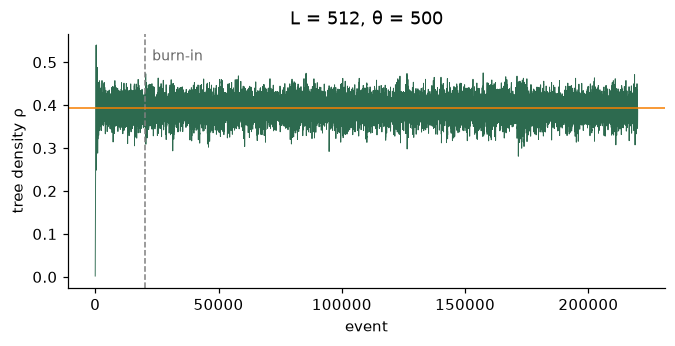

stationary mean density ρ = 0.3928 ± 0.0232 (s.d.)


In [2]:
warm, result = run(L, THETA, EVENTS, BURN_IN, rng)
density = np.concatenate([warm.tree_density, result.tree_density])
rho = result.tree_density.mean()

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(density, lw=0.6, color="#2d6a4f")
ax.axvline(BURN_IN, color="0.5", ls="--", lw=1)
ax.axhline(rho, color="#f77f00", lw=1)
ax.annotate("burn-in", (BURN_IN, density.max()), xytext=(5, -10), textcoords="offset points",
            color="0.4", fontsize=9)
ax.set(xlabel="event", ylabel="tree density ρ", title=f"L = {L}, θ = {THETA}")
plt.show()
print(f"stationary mean density ρ = {rho:.4f} ± {result.tree_density.std():.4f} (s.d.)")

Planting and burning must balance in the stationary state: an event plants θ(1 − ρ)
trees on average and burns ρ⟨s⟩ (the strike hits a tree with probability ρ), so
⟨s⟩ = θ(1 − ρ)/ρ. This is a useful check on the simulation:

In [3]:
sizes = result.fire_sizes
print(f"{sizes.size} fires; mean size {sizes.mean():.1f}, "
      f"balance predicts {THETA * (1 - rho) / rho:.1f}")

78905 fires; mean size 768.7, balance predicts 772.8


## 2. The fire-size distribution

The fire-size distribution is a power law n(s) ∝ s^−τ up to a cutoff that grows with θ.
Fitting τ by least squares on a log–log histogram is biased and gives no reliable error bar,
so we use the discrete maximum-likelihood estimator, restricted to the window
s_min ≤ s ≤ θ below the cutoff. s_min is chosen to minimise the Kolmogorov–Smirnov distance
between the data and the fitted model. The log-binned histogram is for the picture only.

τ = 1.134 ± 0.004   window [5, 500], n = 41154 of 78905 fires


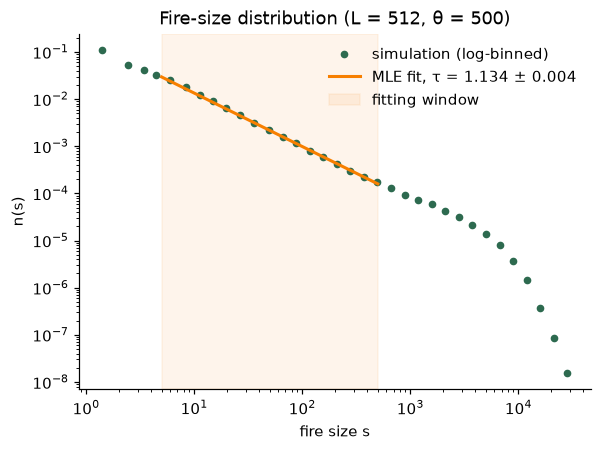

In [4]:
fit = powerlaw.fit(sizes, s_max=THETA)
print(f"τ = {fit.tau:.3f} ± {fit.sigma:.3f}   window [{fit.s_min}, {fit.s_max}], "
      f"n = {fit.n} of {sizes.size} fires")

s, n_s = log_binned(sizes)
in_window = np.mean((sizes >= fit.s_min) & (sizes <= fit.s_max))
line_s = np.arange(fit.s_min, fit.s_max + 1)
pmf = np.diff(np.concatenate([[0.0], powerlaw.cdf(line_s, fit)]))

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(s, n_s, "o", ms=4, color="#2d6a4f", label="simulation (log-binned)")
ax.loglog(line_s, pmf * in_window, color="#f77f00", lw=2,
          label=f"MLE fit, τ = {fit.tau:.3f} ± {fit.sigma:.3f}")
ax.axvspan(fit.s_min, fit.s_max, color="#f77f00", alpha=0.08, label="fitting window")
ax.set(xlabel="fire size s", ylabel="n(s)", title=f"Fire-size distribution (L = {L}, θ = {THETA})")
ax.legend(frameon=False)
if not QUICK:
    fig.savefig(ASSETS / "fire-size-distribution.png", bbox_inches="tight", dpi=150)
plt.show()

For the two-dimensional model, published estimates put τ at around 1.1–1.2 (see
Clar, Drossel & Schwabl 1996 for a review), consistent with the fit above.

## 3. The cutoff: dependence on θ and L

θ sets the typical fire size, and so the position of the cutoff: the more trees are planted
between strikes, the larger the clusters that build up. Below we vary θ at fixed L; the
power-law region extends, and the cutoff moves right, roughly in proportion to θ. The lattice
must be large enough that fires of size ~θ do not feel its finite size, which is why L is
varied as well.

Note that the fitted τ does not settle on a single value as θ grows: it moves by a few
hundredths, by more than its statistical error bar. This is a first glimpse of the caveat in
section 4.

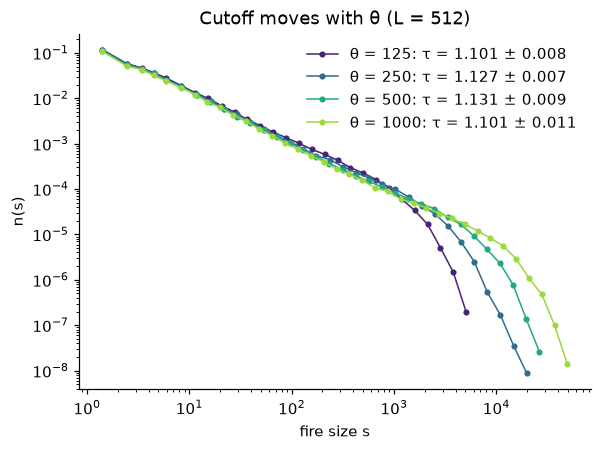

In [5]:
thetas = [25, 50, 100] if QUICK else [125, 250, 500, 1000]
fig, ax = plt.subplots(figsize=(6, 4.2))
colours = plt.cm.viridis(np.linspace(0.1, 0.85, len(thetas)))
for theta, colour in zip(thetas, colours, strict=True):
    _, r = run(L, theta, EVENTS // 2, BURN_IN, rng)
    theta_fit = powerlaw.fit(r.fire_sizes, s_max=theta)
    s, n_s = log_binned(r.fire_sizes)
    ax.loglog(s, n_s, "o-", ms=3, lw=1, color=colour,
              label=f"θ = {theta}: τ = {theta_fit.tau:.3f} ± {theta_fit.sigma:.3f}")
ax.set(xlabel="fire size s", ylabel="n(s)", title=f"Cutoff moves with θ (L = {L})")
ax.legend(frameon=False)
if not QUICK:
    fig.savefig(ASSETS / "theta-dependence.png", bbox_inches="tight", dpi=150)
plt.show()

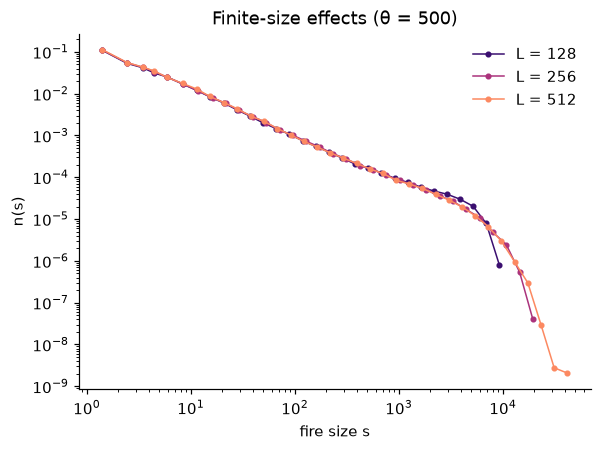

In [6]:
sizes_L = [32, 64] if QUICK else [128, 256, 512]
fig, ax = plt.subplots(figsize=(6, 4.2))
colours = plt.cm.magma(np.linspace(0.2, 0.75, len(sizes_L)))
for size, colour in zip(sizes_L, colours, strict=True):
    _, r = run(size, THETA, EVENTS // 2, BURN_IN, rng)
    s, n_s = log_binned(r.fire_sizes)
    ax.loglog(s, n_s, "o-", ms=3, lw=1, color=colour, label=f"L = {size}")
ax.set(xlabel="fire size s", ylabel="n(s)", title=f"Finite-size effects (θ = {THETA})")
ax.legend(frameon=False)
plt.show()

On small lattices the largest fires span the system: a bump appears near s ~ L², and the
distribution no longer reflects the bulk behaviour. Fitting only below θ, on a lattice
with θ ≪ L², keeps the estimate of τ clear of both effects.

## 4. Caveat: is the model really critical?

The model was introduced as an example of self-organised criticality, and at the θ and L
reachable here it shows a clean power law. But simulations at much larger θ and L tell a
more complicated story. Grassberger (2002) found that the effective exponent keeps drifting
as θ grows, and Pruessner & Jensen (2002) showed that the standard finite-size scaling ansatz
breaks down: on very large scales the model is not simply critical. The exponent
fitted here is therefore best read as an effective exponent for this range of θ, not a
universal constant.

## References

- B. Drossel & F. Schwabl, *Self-organized critical forest-fire model*, Phys. Rev. Lett.
  **69**, 1629 (1992).
- S. Clar, B. Drossel & F. Schwabl, *Forest fires and other examples of self-organized
  criticality*, J. Phys.: Condens. Matter **8**, 6803 (1996).
- P. Grassberger, *Critical behaviour of the Drossel–Schwabl forest fire model*, New J. Phys.
  **4**, 17 (2002).
- G. Pruessner & H. J. Jensen, *Broken scaling in the forest-fire model*, Phys. Rev. E **65**,
  056707 (2002).
- A. Clauset, C. R. Shalizi & M. E. J. Newman, *Power-law distributions in empirical data*,
  SIAM Rev. **51**, 661 (2009).